In [4]:
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass").glob("*_phaseclass.csv"))

data = []

for file in files:
    df = pd.read_csv(file)
    df["run"] = file.stem
    data.append(df)

data = pd.concat(data, ignore_index=True)

print(data.shape)
print(data["phase_label"].value_counts())

(545775, 26)
phase_label
NORMAL              531956
INITIATING_DRIFT     13535
SUSTAINED_DRIFT        284
Name: count, dtype: int64


In [5]:
features = [
    "Vx_mps",
    "Vy_mps",
    "yawRate_radps",
    "roadWheelAngle_rad",
    "ayCG_mps2",
    "axCG_mps2",
    "throttleCmd_percent",
    "brake_fl_bar",
    "brake_fr_bar",
    "brake_rl_bar",
    "brake_rr_bar",
    "engineTorque_Nm",
    "engine_rpm",
    "wheelspeed_fl",
    "wheelspeed_fr",
    "wheelspeed_rl",
    "wheelspeed_rr",
    "LSDengage_percent",
    "rollRate_radps",
    "pitchRate_radps"
]

X = data[features]
y = data["phase_label"]

print(X.shape)
print(y.value_counts())

(545775, 20)
phase_label
NORMAL              531956
INITIATING_DRIFT     13535
SUSTAINED_DRIFT        284
Name: count, dtype: int64


In [6]:
X = X.replace([np.inf, -np.inf], np.nan)

valid = X.notna().all(axis=1) & y.notna()

X = X.loc[valid]
y = y.loc[valid]

print("Samples:", len(X))

Samples: 545775


In [7]:
from sklearn.model_selection import GroupShuffleSplit

groups = data.loc[X.index, "run"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining runs:")
print(groups.iloc[train_idx].unique())

print("\nTesting runs:")
print(groups.iloc[test_idx].unique())

Training samples: 432382
Testing samples: 113393

Training runs:
['2023-10_3_phaseclass' '2023-10_4_phaseclass' '2023-10_5_phaseclass'
 '2023-10_6_phaseclass' '2023-10_7_phaseclass' '2023-10_8_phaseclass'
 '2023-10_phaseclass' '2023-11_10_phaseclass' '2023-11_11_phaseclass'
 '2023-11_1_phaseclass' '2023-11_3_phaseclass' '2023-11_5_phaseclass'
 '2023-11_6_phaseclass' '2023-11_7_phaseclass' '2023-11_8_phaseclass'
 '2023-11_9_phaseclass' '2023-11_phaseclass']

Testing runs:
['2023-10_1_phaseclass' '2023-10_2_phaseclass' '2023-10_9_phaseclass'
 '2023-11_2_phaseclass' '2023-11_4_phaseclass']


In [8]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

print("Random Forest trained")

Random Forest trained


In [13]:
import joblib

joblib.dump(rf, "random_forest_model.pkl")

print("Model saved")

Model saved


In [9]:
y_pred = rf.predict(X_test)

print(y_pred[:20])

['NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL']


In [10]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy:
0.977167902780595

Classification Report:
                  precision    recall  f1-score   support

INITIATING_DRIFT       0.53      0.82      0.65      2884
          NORMAL       1.00      0.98      0.99    110480
 SUSTAINED_DRIFT       0.09      0.03      0.05        29

        accuracy                           0.98    113393
       macro avg       0.54      0.61      0.56    113393
    weighted avg       0.98      0.98      0.98    113393



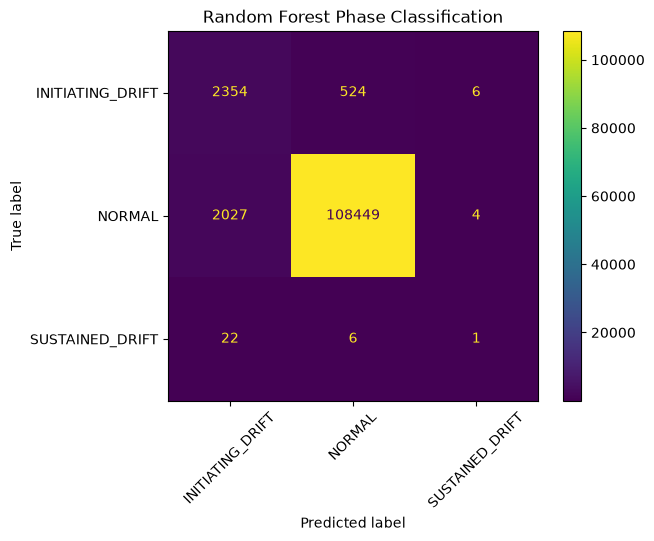

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)

plt.title("Random Forest Phase Classification")
plt.grid(False)
plt.show()

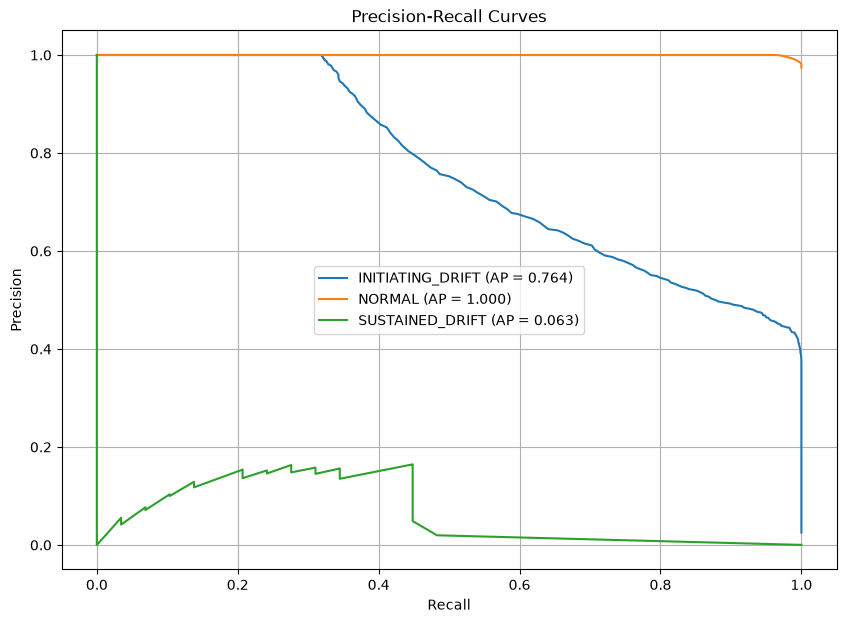

In [12]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

classes = rf.classes_

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

y_prob = rf.predict_proba(X_test)

plt.figure(figsize=(10, 7))

for i, cls in enumerate(classes):

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{cls} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid()
plt.show()

_________________________________________TRAINING ON LABEL2___________________________________________

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

files = sorted(Path("phaseclass_v2").glob("*_phaseclass.csv"))

data = []

for file in files:
    df = pd.read_csv(file)
    df["run"] = file.stem
    data.append(df)

data = pd.concat(data, ignore_index=True)

print(data.shape)
print(data["phase_label"].value_counts())

(545775, 31)
phase_label
NORMAL              541144
SUSTAINED_DRIFT       3181
INITIATING_DRIFT      1450
Name: count, dtype: int64


In [2]:
features = [
    "Vx_mps",
    "Vy_mps",
    "yawRate_radps",
    "roadWheelAngle_rad",
    "ayCG_mps2",
    "axCG_mps2",
    "throttleCmd_percent",
    "brake_fl_bar",
    "brake_fr_bar",
    "brake_rl_bar",
    "brake_rr_bar",
    "engineTorque_Nm",
    "engine_rpm",
    "wheelspeed_fl",
    "wheelspeed_fr",
    "wheelspeed_rl",
    "wheelspeed_rr",
    "LSDengage_percent",
    "rollRate_radps",
    "pitchRate_radps"
]

X = data[features]
y = data["phase_label"]

print(X.shape)
print(y.value_counts())

(545775, 20)
phase_label
NORMAL              541144
SUSTAINED_DRIFT       3181
INITIATING_DRIFT      1450
Name: count, dtype: int64


In [3]:
X = X.replace([np.inf, -np.inf], np.nan)

valid = X.notna().all(axis=1) & y.notna()

X = X.loc[valid]
y = y.loc[valid]

print("Samples:", len(X))

Samples: 545775


In [4]:
from sklearn.model_selection import GroupShuffleSplit

groups = data.loc[X.index, "run"]

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining runs:")
print(groups.iloc[train_idx].unique())

print("\nTesting runs:")
print(groups.iloc[test_idx].unique())

Training samples: 432382
Testing samples: 113393

Training runs:
['2023-10_3_phaseclass' '2023-10_4_phaseclass' '2023-10_5_phaseclass'
 '2023-10_6_phaseclass' '2023-10_7_phaseclass' '2023-10_8_phaseclass'
 '2023-10_phaseclass' '2023-11_10_phaseclass' '2023-11_11_phaseclass'
 '2023-11_1_phaseclass' '2023-11_3_phaseclass' '2023-11_5_phaseclass'
 '2023-11_6_phaseclass' '2023-11_7_phaseclass' '2023-11_8_phaseclass'
 '2023-11_9_phaseclass' '2023-11_phaseclass']

Testing runs:
['2023-10_1_phaseclass' '2023-10_2_phaseclass' '2023-10_9_phaseclass'
 '2023-11_2_phaseclass' '2023-11_4_phaseclass']


In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

print("Training class distribution:")
print(y_train.value_counts())

print("\nCalculated class weights:")
for cls, weight in class_weights.items():
    print(f"{cls}: {weight:.3f}")

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    class_weight=class_weights
)

rf.fit(X_train, y_train)

print("\nWeighted Random Forest trained.")

Training class distribution:
phase_label
NORMAL              428556
SUSTAINED_DRIFT       2631
INITIATING_DRIFT      1195
Name: count, dtype: int64

Calculated class weights:
INITIATING_DRIFT: 120.609
NORMAL: 0.336
SUSTAINED_DRIFT: 54.780

Weighted Random Forest trained.


In [12]:
import joblib

joblib.dump(rf, "random_forest_model2.pkl")

print("Model saved")

Model saved


In [13]:
y_pred = rf.predict(X_test)

print(y_pred[:20])

['NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL'
 'NORMAL' 'NORMAL' 'NORMAL' 'NORMAL']


In [16]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("Accuracy:")
print(accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)

Accuracy:
0.9947439436296773

Classification Report:
                  precision    recall  f1-score   support

INITIATING_DRIFT       0.55      0.54      0.55       255
          NORMAL       1.00      1.00      1.00    112588
 SUSTAINED_DRIFT       0.97      0.34      0.50       550

        accuracy                           0.99    113393
       macro avg       0.84      0.63      0.68    113393
    weighted avg       0.99      0.99      0.99    113393



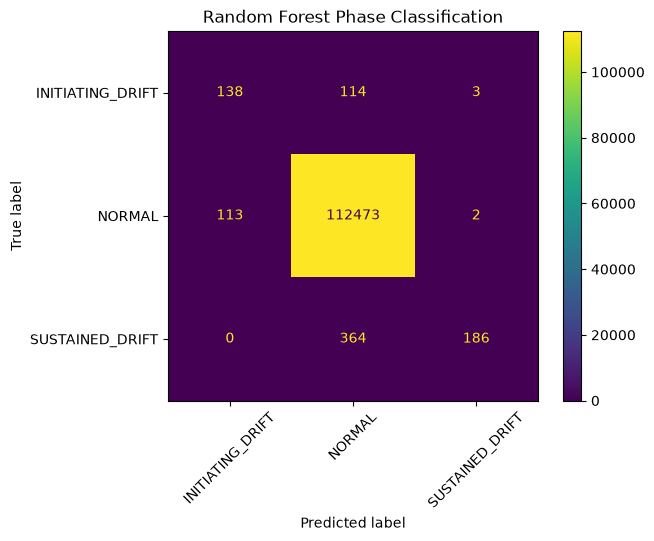

In [17]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    xticks_rotation=45
)

plt.title("Random Forest Phase Classification")
plt.grid(False)
plt.show()

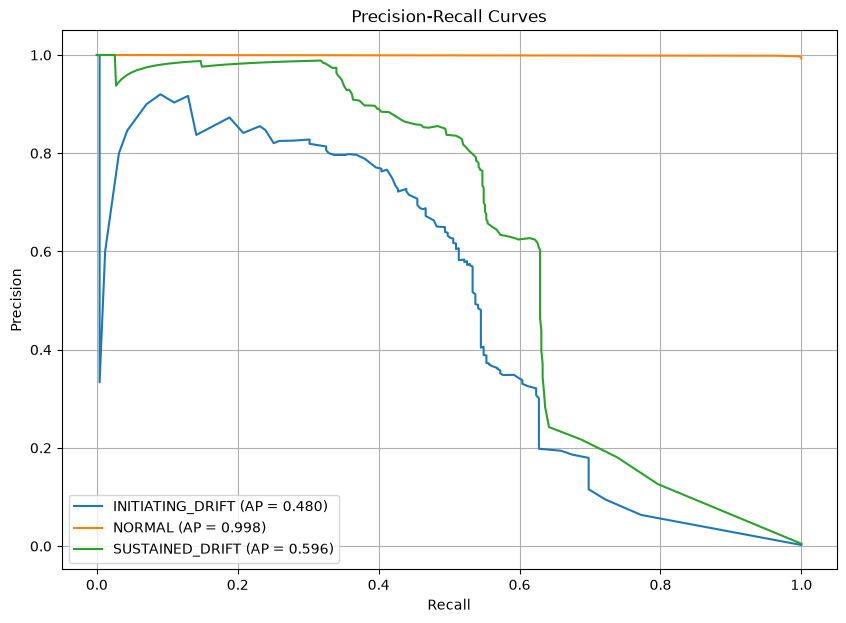

In [19]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

classes = rf.classes_

y_test_bin = label_binarize(
    
    y_test,
    classes=classes
)

y_prob = rf.predict_proba(X_test)

plt.figure(figsize=(10, 7))

for i, cls in enumerate(classes):

    precision, recall, _ = precision_recall_curve(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    ap = average_precision_score(
        y_test_bin[:, i],
        y_prob[:, i]
    )

    plt.plot(
        recall,
        precision,
        label=f"{cls} (AP = {ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves")
plt.legend()
plt.grid()
plt.show()